In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data.load_data import load_ratings, load_user_profiles
from src.models.clustering import (
    prepare_user_features,
    apply_pca,
    calculate_kmeans_inertia,
    fit_kmeans,
)

from src.recommenders.clustering_based import (
    ClusterBasedRecommender,
)

DATA_DIR = PROJECT_ROOT / "data" / "raw"

In [2]:
user_profiles = load_user_profiles(DATA_DIR)
ratings = load_ratings(DATA_DIR)

user_profiles.shape, ratings.shape

((33901, 15), (233306, 3))

In [3]:
scaled_features, scaler = prepare_user_features(
    user_profiles
)

scaled_features.shape

(33901, 14)

In [4]:
pca_features, pca = apply_pca(
    scaled_features,
    variance_threshold=0.90,
)

pca_features.shape

(33901, 9)

In [5]:
cluster_results = calculate_kmeans_inertia(
    pca_features,
    range(1, 30),
)

cluster_results.head()

,n_clusters,inertia
0,1,440095.114537
1,2,363750.926858
2,3,317563.294217
3,4,282430.768403
4,5,248620.434782


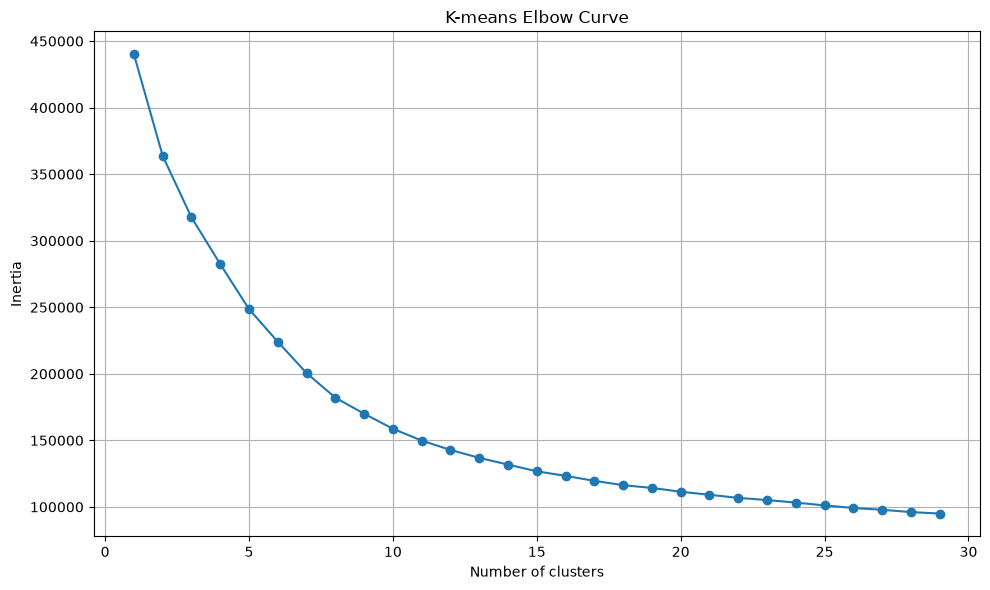

In [6]:
plt.figure(figsize=(10, 6))

plt.plot(
    cluster_results["n_clusters"],
    cluster_results["inertia"],
    marker="o",
)

plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("K-means Elbow Curve")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "kmeans_elbow_curve.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [7]:
clustered_features, kmeans = fit_kmeans(
    pca_features,
    n_clusters=12,
)

clustered_features.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,cluster
user,,,,,,,,,,
2,17.772494,0.200681,1.730609,2.567359,-3.825814,-2.707154,0.681042,2.312613,0.868272,9
4,7.145199,-2.847481,2.358636,-0.576654,0.398803,0.134533,0.549769,0.469033,0.033405,8
5,11.363270,1.873619,-1.522077,1.076144,-1.711688,-0.883212,1.677582,2.937669,2.097639,9
7,-1.834033,-0.277462,0.564905,0.053470,-0.064440,-0.165757,0.030956,0.039519,0.210887,1
8,-1.049125,-0.684767,1.072765,0.006371,-0.005695,-0.118686,0.118559,0.559292,0.186379,1


In [8]:
cluster_sizes = (
    clustered_features["cluster"]
    .value_counts()
    .sort_index()
)

cluster_sizes

cluster
0      4136
1     10267
2      1374
3      2917
4        20
5       566
6      2820
7      2969
8       572
9       407
10     2645
11     5208
Name: count, dtype: int64

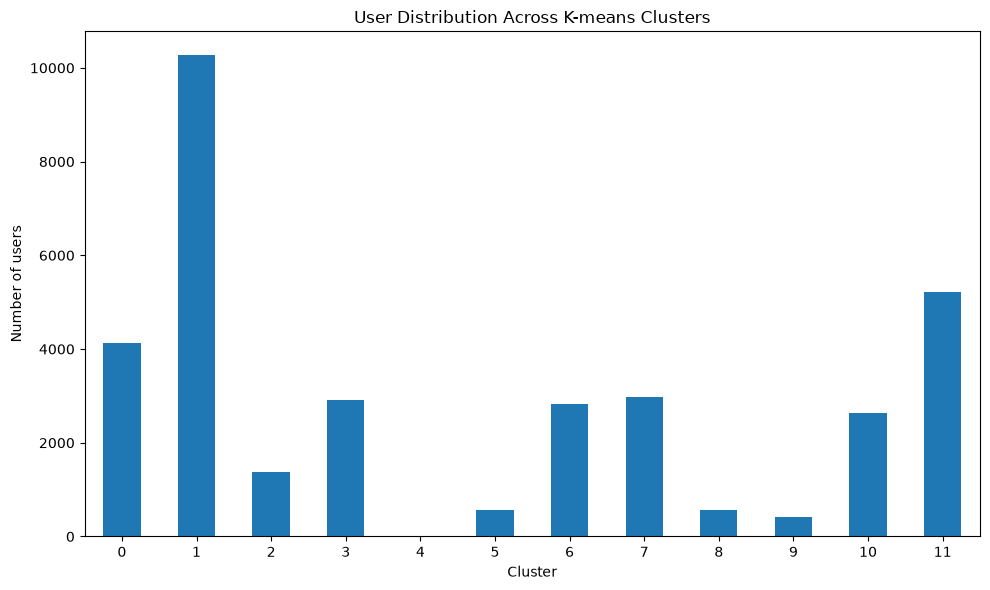

In [9]:
plt.figure(figsize=(10, 6))

cluster_sizes.plot(
    kind="bar",
)

plt.xlabel("Cluster")
plt.ylabel("Number of users")
plt.title("User Distribution Across K-means Clusters")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "cluster_size_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [10]:
cluster_recommender = ClusterBasedRecommender(
    top_n=10
)

cluster_recommender.fit(
    user_clusters=clustered_features,
    ratings=ratings,
)

In [12]:
user_id = user_profiles["user"].iloc[0]

user_id

np.int64(2)

In [13]:
cluster_recommendations = cluster_recommender.recommend(
    user_id=user_id,
    ratings=ratings,
)

cluster_recommendations

,COURSE_ID,rating_count
0,DS0101EN,319
1,ML0101ENv3,283
2,DS0105EN,244
3,CC0101EN,238
4,BC0201EN,237
5,CO0201EN,218
6,CO0301EN,214
7,CO0401EN,190
8,BD0115EN,189
9,CC0103EN,175


In [15]:
from src.data.load_data import (
    load_courses,
    load_ratings,
    load_user_profiles,
)

courses = load_courses(DATA_DIR)

In [16]:
cluster_recommendations = cluster_recommendations.merge(
    courses[["COURSE_ID", "TITLE"]],
    on="COURSE_ID",
    how="left",
)

cluster_recommendations = cluster_recommendations[
    ["COURSE_ID", "TITLE", "rating_count"]
]

cluster_recommendations

,COURSE_ID,TITLE,rating_count
0,DS0101EN,introduction to data science,319
1,ML0101ENv3,machine learning with python,283
2,DS0105EN,data science hands on with open source tools,244
3,CC0101EN,introduction to cloud,238
4,BC0201EN,ibm blockchain foundation developer,237
5,CO0201EN,container kubernetes essentials with ibm cloud,218
6,CO0301EN,getting started with microservices with istio ...,214
7,CO0401EN,beyond the basics istio and ibm cloud kuberne...,190
8,BD0115EN,mapreduce and yarn,189
9,CC0103EN,ibm cloud essentials v3,175


In [17]:
cluster_recommendation_counts = []

for current_user_id in user_profiles["user"]:
    recommendations = cluster_recommender.recommend(
        user_id=current_user_id,
        ratings=ratings,
    )

    cluster_recommendation_counts.append(
        len(recommendations)
    )

average_cluster_recommendations = sum(
    cluster_recommendation_counts
) / len(cluster_recommendation_counts)

average_cluster_recommendations

10.0